<a href="https://colab.research.google.com/github/devcodes28/AI-ML-Lab-24CSP503/blob/main/ANN_Backpropagation_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Artificial Neural Network from Scratch with Backpropagation
**Dataset:** Pima Indians Diabetes Database (Kaggle: `uciml/pima-indians-diabetes-database`) – binary classification (diabetic / non‑diabetic) from 8 medical predictors.

**Pipeline**
1. Load data  →  2. Exploratory analysis  →  3. Preprocessing (missing values, outliers, scaling, split)
4. ANN implemented **only with NumPy** (forward pass, backpropagation, mini‑batch gradient descent)
5. Gradient checking (verifies backprop is correct)  →  6. Training & learning curves
7. Evaluation (confusion matrix, ROC, PR curve, metrics)  →  8. Hyper‑parameter experiments  →  9. Comparison with scikit‑learn

### Backpropagation recap
For layer *l* with weights W, bias b, activation g:
- Forward: Z⁽ˡ⁾ = A⁽ˡ⁻¹⁾W⁽ˡ⁾ + b⁽ˡ⁾,  A⁽ˡ⁾ = g(Z⁽ˡ⁾)
- Output layer (sigmoid + binary cross‑entropy): δ⁽ᴸ⁾ = A⁽ᴸ⁾ − y
- Hidden layers: δ⁽ˡ⁾ = (δ⁽ˡ⁺¹⁾ W⁽ˡ⁺¹⁾ᵀ) ⊙ g′(Z⁽ˡ⁾)
- Gradients: ∂L/∂W⁽ˡ⁾ = A⁽ˡ⁻¹⁾ᵀ δ⁽ˡ⁾ / m (+ λW/m for L2),  ∂L/∂b⁽ˡ⁾ = mean(δ⁽ˡ⁾)
- Update: W ← W − η·∂L/∂W

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
SEED = 42
np.random.seed(SEED)

## 1. Load the dataset
The loader tries (a) a local Kaggle `diabetes.csv`, (b) `kagglehub` download, (c) a public mirror of the same data on GitHub.

In [ ]:
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
MIRROR = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

def load_pima():
    if os.path.exists("diabetes.csv"):
        print("Loaded local Kaggle file diabetes.csv"); return pd.read_csv("diabetes.csv")
    try:
        import kagglehub
        p = kagglehub.dataset_download("uciml/pima-indians-diabetes-database")
        print("Downloaded with kagglehub"); return pd.read_csv(os.path.join(p, "diabetes.csv"))
    except Exception as e:
        print("kagglehub unavailable -> using public mirror of the same dataset")
        return pd.read_csv(MIRROR, header=None, names=COLS)

df = load_pima()
print("Shape:", df.shape)
df.head()

kagglehub unavailable -> using public mirror of the same dataset
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Exploratory Data Analysis

In [ ]:
display(df.describe().T)
print("\nMissing (NaN) values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing (NaN) values per column:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


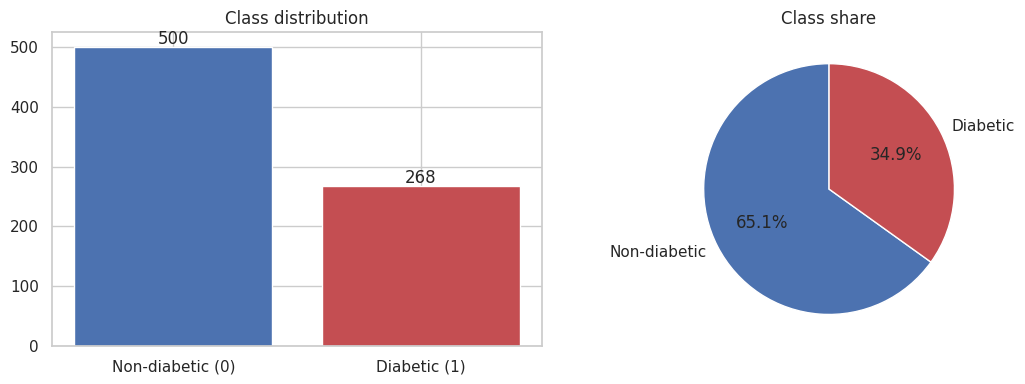

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = df["Outcome"].value_counts().sort_index()
ax[0].bar(["Non-diabetic (0)", "Diabetic (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values): ax[0].text(i, v + 5, str(v), ha="center")
ax[0].set_title("Class distribution")
ax[1].pie(counts.values, labels=["Non-diabetic", "Diabetic"], autopct="%1.1f%%", colors=["#4C72B0", "#C44E52"], startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

**Hidden missing values:** In this dataset, a value of `0` for Glucose, BloodPressure, SkinThickness, Insulin and BMI is physiologically impossible – it encodes *missing*.

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


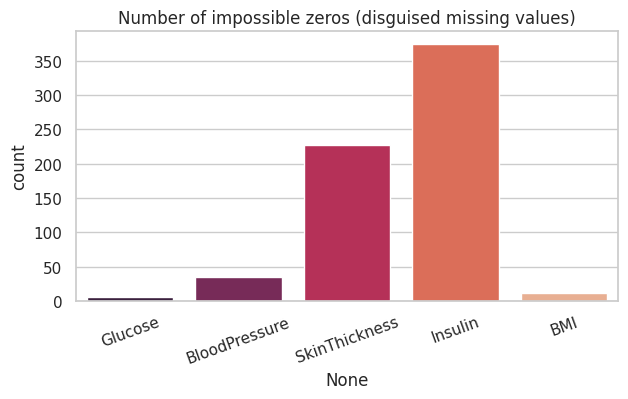

In [ ]:
zero_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts = (df[zero_cols] == 0).sum()
print(zero_counts)
plt.figure(figsize=(7, 3.5))
sns.barplot(x=zero_counts.index, y=zero_counts.values, palette="rocket")
plt.title("Number of impossible zeros (disguised missing values)"); plt.ylabel("count"); plt.xticks(rotation=20)
plt.show()

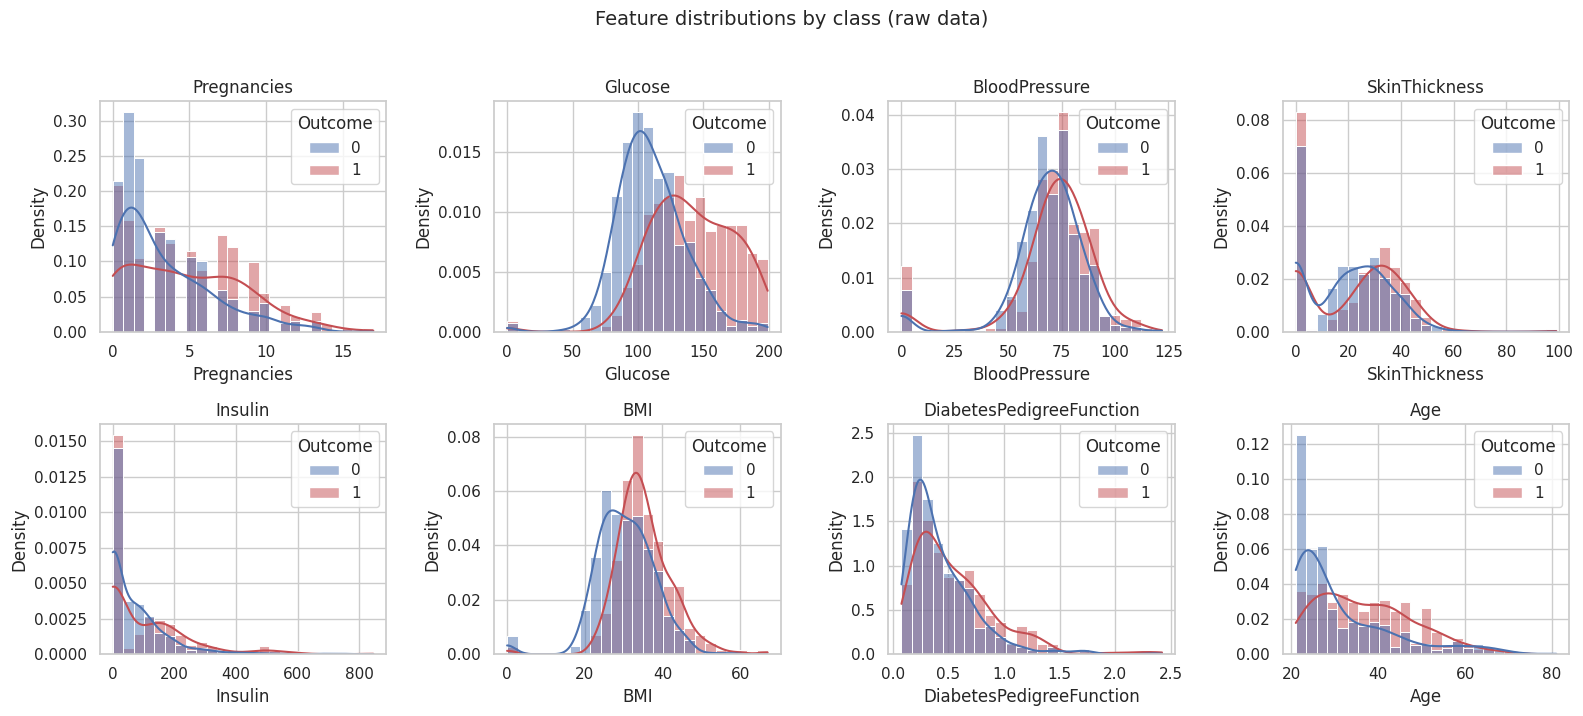

In [ ]:
features = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, bins=25, ax=ax, palette=["#4C72B0", "#C44E52"], stat="density", common_norm=False)
    ax.set_title(col)
plt.suptitle("Feature distributions by class (raw data)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

## 3. Preprocessing

Steps (to avoid **data leakage**, medians and scaling statistics are computed on the training set only):
1. Replace impossible zeros with `NaN`
2. Stratified split → train 70 % / validation 15 % / test 15 %
3. Median imputation (train medians)
4. Outlier handling by IQR **winsorizing** (clip to train‑set bounds)
5. Standardisation (zero mean, unit variance)

In [ ]:
data = df.copy()
data[zero_cols] = data[zero_cols].replace(0, np.nan)
print("Missing after zero->NaN:\n", data.isna().sum()[zero_cols])

X = data[features]; y = data["Outcome"].values

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"\nTrain {X_train.shape}, Val {X_val.shape}, Test {X_test.shape}")
print("Positive rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

Missing after zero->NaN:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Train (537, 8), Val (115, 8), Test (116, 8)
Positive rate  train/val/test: 0.348 0.348 0.353


Outliers clipped per feature (train):
 Pregnancies                   2
Glucose                       0
BloodPressure                11
SkinThickness                60
Insulin                     232
BMI                           8
DiabetesPedigreeFunction     16
Age                           5
dtype: int64


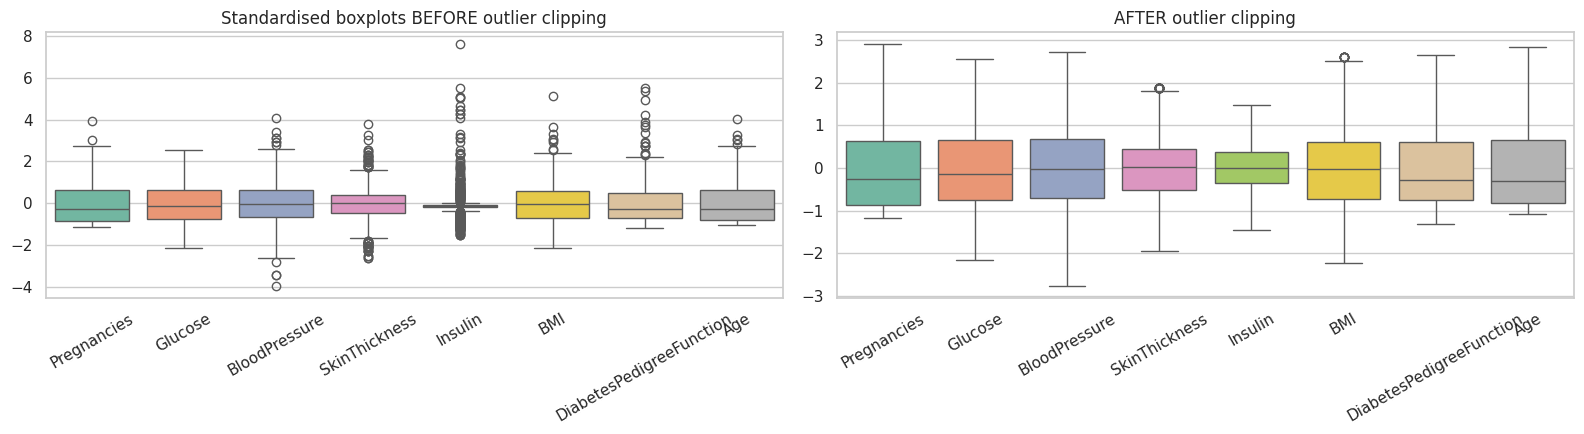

In [ ]:
# 3. Median imputation using TRAIN medians
medians = X_train.median()
X_train_i, X_val_i, X_test_i = (d.fillna(medians) for d in (X_train, X_val, X_test))

# Boxplots BEFORE outlier treatment
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.boxplot(data=(X_train_i - X_train_i.mean()) / X_train_i.std(), ax=ax[0], palette="Set2")
ax[0].set_title("Standardised boxplots BEFORE outlier clipping"); ax[0].tick_params(axis="x", rotation=30)

# 4. IQR winsorizing with train bounds
q1, q3 = X_train_i.quantile(0.25), X_train_i.quantile(0.75)
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((X_train_i < lo) | (X_train_i > hi)).sum()
print("Outliers clipped per feature (train):\n", n_out)
X_train_c, X_val_c, X_test_c = (d.clip(lo, hi, axis=1) for d in (X_train_i, X_val_i, X_test_i))

sns.boxplot(data=(X_train_c - X_train_c.mean()) / X_train_c.std(), ax=ax[1], palette="Set2")
ax[1].set_title("AFTER outlier clipping"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

Train mean (~0): [-0.  0.  0. -0. -0.  0.  0. -0.]
Train std  (~1): [1. 1. 1. 1. 1. 1. 1. 1.]


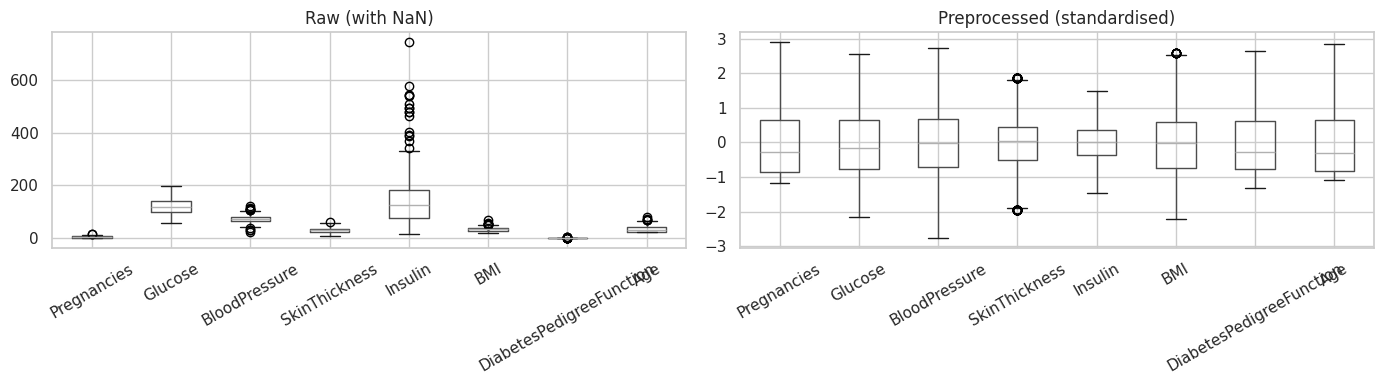

In [ ]:
# 5. Standardisation
scaler = StandardScaler().fit(X_train_c)
Xtr, Xva, Xte = scaler.transform(X_train_c), scaler.transform(X_val_c), scaler.transform(X_test_c)
ytr, yva, yte = y_train.reshape(-1, 1), y_val.reshape(-1, 1), y_test.reshape(-1, 1)

print("Train mean (~0):", Xtr.mean(0).round(2))
print("Train std  (~1):", Xtr.std(0).round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, d, t in zip(ax, [X_train, pd.DataFrame(Xtr, columns=features)], ["Raw (with NaN)", "Preprocessed (standardised)"]):
    d.boxplot(ax=a, rot=30); a.set_title(t)
plt.tight_layout(); plt.show()

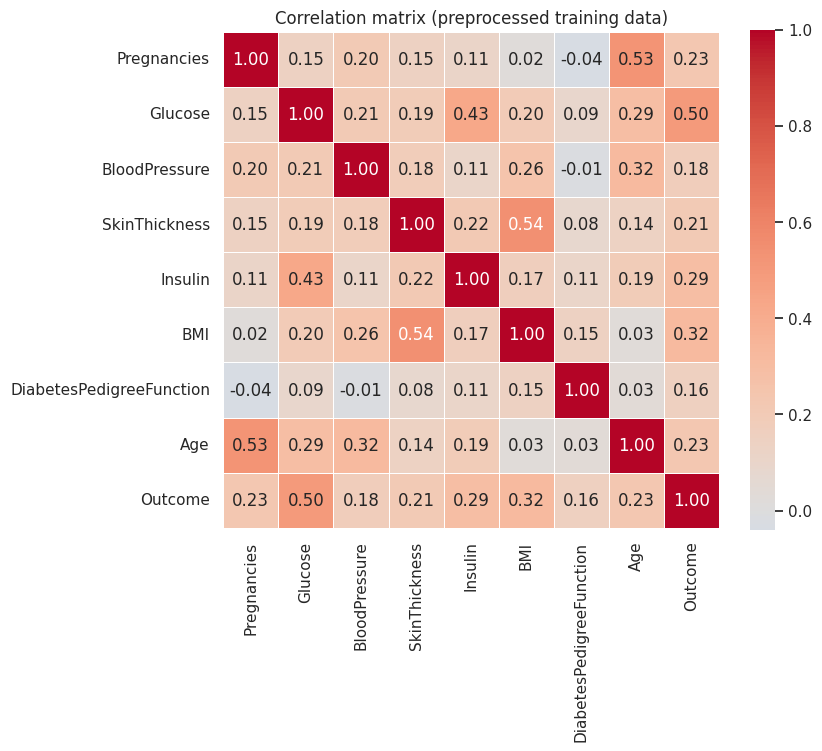

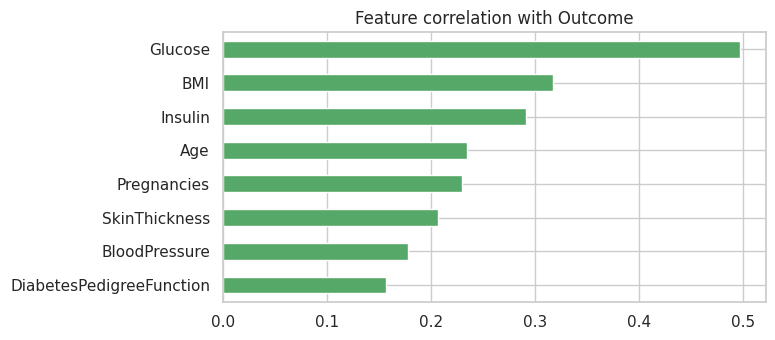

In [ ]:
clean = pd.DataFrame(Xtr, columns=features); clean["Outcome"] = y_train
corr = clean.corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("Correlation matrix (preprocessed training data)"); plt.show()

corr["Outcome"].drop("Outcome").sort_values().plot(kind="barh", figsize=(7, 3.5), color="#55A868", title="Feature correlation with Outcome")
plt.show()

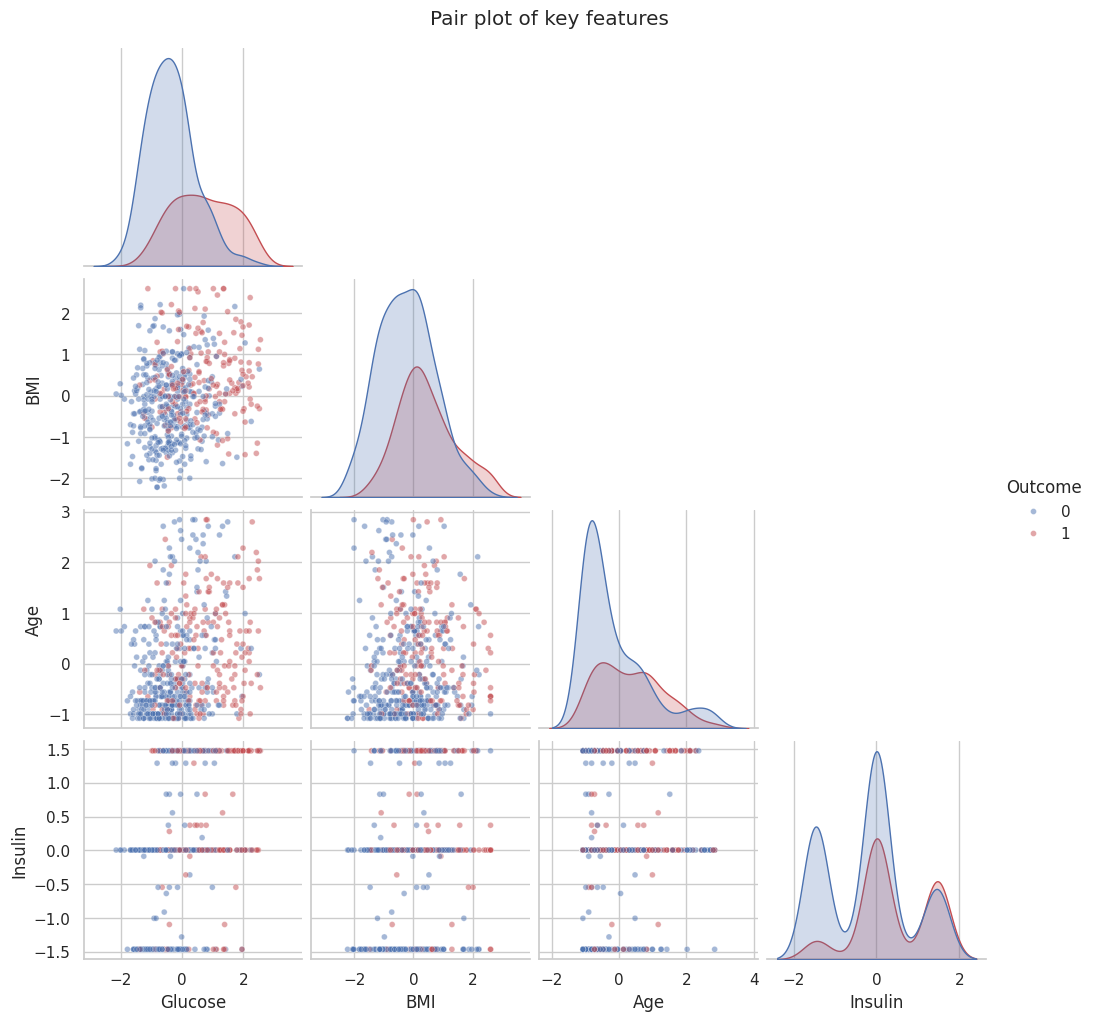

In [ ]:
sns.pairplot(clean[["Glucose", "BMI", "Age", "Insulin", "Outcome"]], hue="Outcome", palette=["#4C72B0", "#C44E52"], plot_kws=dict(alpha=.5, s=18), corner=True)
plt.suptitle("Pair plot of key features", y=1.02); plt.show()

## 4. ANN implementation (NumPy only)

In [ ]:
# ---------- Activation functions & derivatives ----------
def sigmoid(z):      return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
def sigmoid_d(z):    s = sigmoid(z); return s * (1 - s)
def relu(z):         return np.maximum(0, z)
def relu_d(z):       return (z > 0).astype(float)
def tanh(z):         return np.tanh(z)
def tanh_d(z):       return 1 - np.tanh(z) ** 2

ACT = {"sigmoid": (sigmoid, sigmoid_d), "relu": (relu, relu_d), "tanh": (tanh, tanh_d)}

class NeuralNetwork:
    """Fully connected feed-forward network trained with backpropagation.
    Hidden layers: configurable activation. Output: sigmoid + binary cross-entropy."""

    def __init__(self, layer_sizes, activation="relu", lr=0.05, l2=0.0, seed=42):
        self.sizes, self.act_name, self.lr, self.l2 = layer_sizes, activation, lr, l2
        self.act, self.act_d = ACT[activation]
        rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            # He init for ReLU, Xavier otherwise
            scale = np.sqrt(2.0 / n_in) if activation == "relu" else np.sqrt(1.0 / n_in)
            self.W.append(rng.normal(0, scale, (n_in, n_out)))
            self.b.append(np.zeros((1, n_out)))
        self.history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "grad_norm": []}

    # ---------- forward pass ----------
    def forward(self, X):
        self.Z, self.A = [], [X]
        a = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            a = sigmoid(z) if i == len(self.W) - 1 else self.act(z)
            self.Z.append(z); self.A.append(a)
        return a

    # ---------- loss ----------
    def loss(self, y_hat, y):
        eps = 1e-12
        bce = -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))
        reg = self.l2 / (2 * len(y)) * sum(np.sum(W ** 2) for W in self.W)
        return bce + reg

    # ---------- backpropagation ----------
    def backward(self, y):
        m = y.shape[0]
        dW, db = [None] * len(self.W), [None] * len(self.W)
        delta = self.A[-1] - y                                  # dL/dZ for sigmoid + BCE
        for l in reversed(range(len(self.W))):
            dW[l] = self.A[l].T @ delta / m + self.l2 * self.W[l] / m
            db[l] = delta.mean(axis=0, keepdims=True)
            if l > 0:
                delta = (delta @ self.W[l].T) * self.act_d(self.Z[l - 1])   # propagate error back
        return dW, db

    def _step(self, dW, db):
        for l in range(len(self.W)):
            self.W[l] -= self.lr * dW[l]
            self.b[l] -= self.lr * db[l]

    # ---------- prediction ----------
    def predict_proba(self, X): return self.forward(X)
    def predict(self, X, thr=0.5): return (self.forward(X) >= thr).astype(int)
    def accuracy(self, X, y): return np.mean(self.predict(X) == y)

    # ---------- training loop (mini-batch gradient descent) ----------
    def fit(self, X, y, X_val=None, y_val=None, epochs=300, batch_size=32, verbose=50, seed=0, patience=None):
        rng = np.random.default_rng(seed)
        n = X.shape[0]
        best, wait, self.best_epoch = np.inf, 0, None
        for ep in range(1, epochs + 1):
            idx = rng.permutation(n)
            for s in range(0, n, batch_size):
                bi = idx[s:s + batch_size]
                self.forward(X[bi])
                dW, db = self.backward(y[bi])
                self._step(dW, db)
            # --- logging (full-data metrics) ---
            p = self.forward(X)
            self.history["train_loss"].append(self.loss(p, y))
            self.history["train_acc"].append(np.mean((p >= .5) == y))
            dW_full, _ = self.backward(y)
            self.history["grad_norm"].append(np.sqrt(sum(np.sum(g ** 2) for g in dW_full)))
            if X_val is not None:
                pv = self.forward(X_val)
                self.history["val_loss"].append(self.loss(pv, y_val))
                self.history["val_acc"].append(np.mean((pv >= .5) == y_val))
            if verbose and (ep % verbose == 0 or ep == 1):
                msg = f"Epoch {ep:4d} | loss {self.history['train_loss'][-1]:.4f} | acc {self.history['train_acc'][-1]:.4f}"
                if X_val is not None:
                    msg += f" | val_loss {self.history['val_loss'][-1]:.4f} | val_acc {self.history['val_acc'][-1]:.4f}"
                print(msg)
            # --- early stopping: keep the weights with the lowest validation loss ---
            if patience and X_val is not None:
                if self.history["val_loss"][-1] < best - 1e-5:
                    best, wait, self.best_epoch = self.history["val_loss"][-1], 0, ep
                    self._best = ([W.copy() for W in self.W], [b.copy() for b in self.b])
                else:
                    wait += 1
                    if wait >= patience:
                        print(f"Early stopping at epoch {ep}; restoring weights from epoch {self.best_epoch}")
                        break
        if patience and X_val is not None and getattr(self, "_best", None):
            self.W, self.b = self._best
        return self

## 5. Gradient checking
We verify our analytic backprop gradients against numerical (finite‑difference) gradients: ∂L/∂θ ≈ [L(θ+ε) − L(θ−ε)] / 2ε. A relative error below ~1e‑7 confirms a correct implementation. (ReLU is not differentiable at exactly 0, so on rare seeds a pre‑activation within ε of the kink can inflate the numerical error; the seed used here avoids that.)

sigmoid  relative error = 5.88e-10  -> PASS
tanh     relative error = 4.75e-10  -> PASS
relu     relative error = 2.98e-10  -> PASS


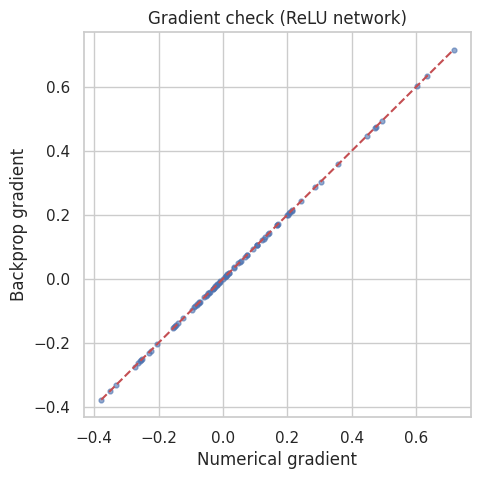

In [ ]:
def gradient_check(activation, eps=1e-6, seed=0):
    nn = NeuralNetwork([8, 6, 4, 1], activation=activation, l2=0.5, seed=seed)
    Xs, ys = Xtr[:20], ytr[:20]
    nn.forward(Xs); dW, db = nn.backward(ys)
    analytic, numeric = [], []
    for params, grads in ((nn.W, dW), (nn.b, db)):
        for P, G in zip(params, grads):
            for idx in np.ndindex(P.shape):
                old = P[idx]
                P[idx] = old + eps; lp = nn.loss(nn.forward(Xs), ys)
                P[idx] = old - eps; lm = nn.loss(nn.forward(Xs), ys)
                P[idx] = old
                numeric.append((lp - lm) / (2 * eps)); analytic.append(G[idx])
    a, n_ = np.array(analytic), np.array(numeric)
    return np.linalg.norm(a - n_) / (np.linalg.norm(a) + np.linalg.norm(n_)), a, n_

for act in ["sigmoid", "tanh", "relu"]:
    err, a, n_ = gradient_check(act)
    print(f"{act:8s} relative error = {err:.2e}  ->", "PASS" if err < 1e-6 else "CHECK")

plt.figure(figsize=(5, 5))
plt.scatter(n_, a, s=12, alpha=.6); lim = [min(a.min(), n_.min()), max(a.max(), n_.max())]
plt.plot(lim, lim, "r--"); plt.xlabel("Numerical gradient"); plt.ylabel("Backprop gradient")
plt.title("Gradient check (ReLU network)"); plt.show()

## 6. Train the network
Architecture: **8 → 16 → 8 → 1** (ReLU hidden layers, sigmoid output), learning rate 0.05, L2 λ = 1.0, batch size 32, early stopping (patience 60 epochs, restores best‑validation weights).

In [ ]:
nn = NeuralNetwork([8, 16, 8, 1], activation="relu", lr=0.05, l2=1.0, seed=SEED)
nn.fit(Xtr, ytr, Xva, yva, epochs=500, batch_size=32, verbose=50, patience=60)

Epoch    1 | loss 0.5960 | acc 0.6518 | val_loss 0.6982 | val_acc 0.6609


Epoch   50 | loss 0.4591 | acc 0.7877 | val_loss 0.5162 | val_acc 0.7304
Epoch  100 | loss 0.4524 | acc 0.7877 | val_loss 0.5173 | val_acc 0.7304


Early stopping at epoch 123; restoring weights from epoch 63


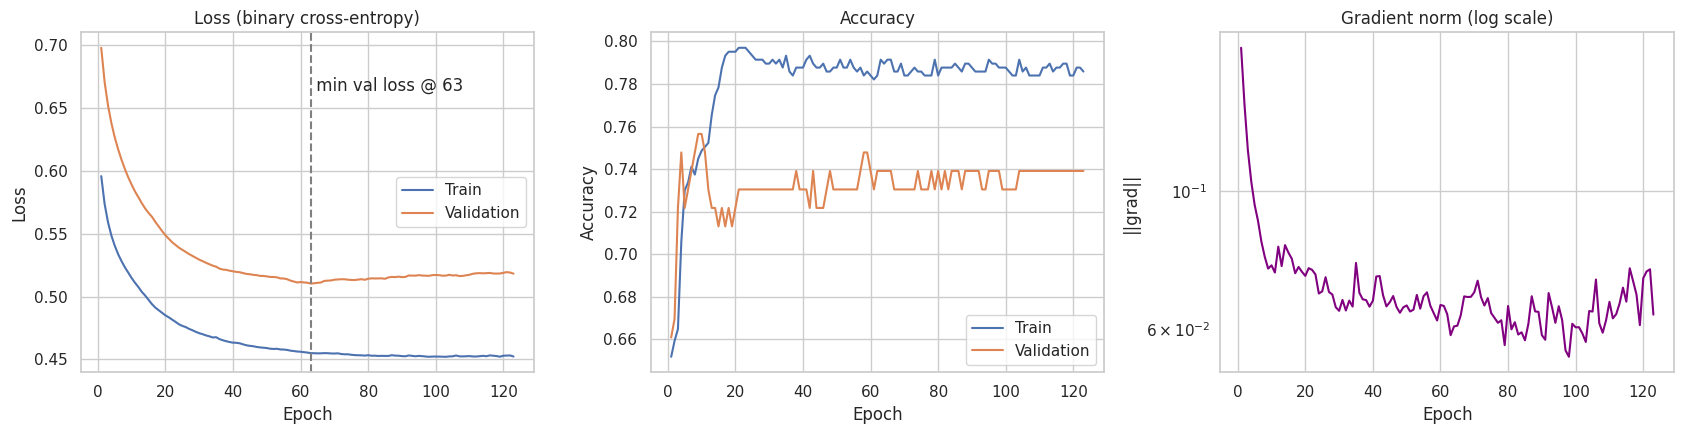

In [ ]:
h = nn.history; ep = np.arange(1, len(h["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(ep, h["train_loss"], label="Train"); ax[0].plot(ep, h["val_loss"], label="Validation")
ax[0].set(title="Loss (binary cross-entropy)", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
ax[1].plot(ep, h["train_acc"], label="Train"); ax[1].plot(ep, h["val_acc"], label="Validation")
ax[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
ax[2].plot(ep, h["grad_norm"], color="purple"); ax[2].set_yscale("log")
ax[2].set(title="Gradient norm (log scale)", xlabel="Epoch", ylabel="||grad||")
best = nn.best_epoch or int(np.argmin(h["val_loss"])) + 1
ax[0].axvline(best, color="gray", ls="--"); ax[0].text(best, ax[0].get_ylim()[1]*.95, f" min val loss @ {best}", va="top")
plt.tight_layout(); plt.show()

## 7. Evaluation on the held‑out test set

In [ ]:
def confusion(y_true, y_pred):
    y_true, y_pred = y_true.ravel(), y_pred.ravel()
    tn = np.sum((y_true == 0) & (y_pred == 0)); fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0)); tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def metrics(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion(y_true, y_pred)
    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if tp + fp else 0
    rec = tp / (tp + fn) if tp + fn else 0
    spec = tn / (tn + fp) if tn + fp else 0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0
    return dict(Accuracy=acc, Precision=prec, Recall=rec, Specificity=spec, F1=f1)

proba_te = nn.predict_proba(Xte); pred_te = nn.predict(Xte)
res = pd.DataFrame({s: metrics(yy, nn.predict(XX)) for s, XX, yy in [("Train", Xtr, ytr), ("Validation", Xva, yva), ("Test", Xte, yte)]}).T
display(res.round(4))

,Accuracy,Precision,Recall,Specificity,F1
Train,0.7914,0.7586,0.5882,0.9000,0.6627
Validation,0.7391,0.6316,0.6000,0.8133,0.6154
Test,0.7414,0.6897,0.4878,0.8800,0.5714


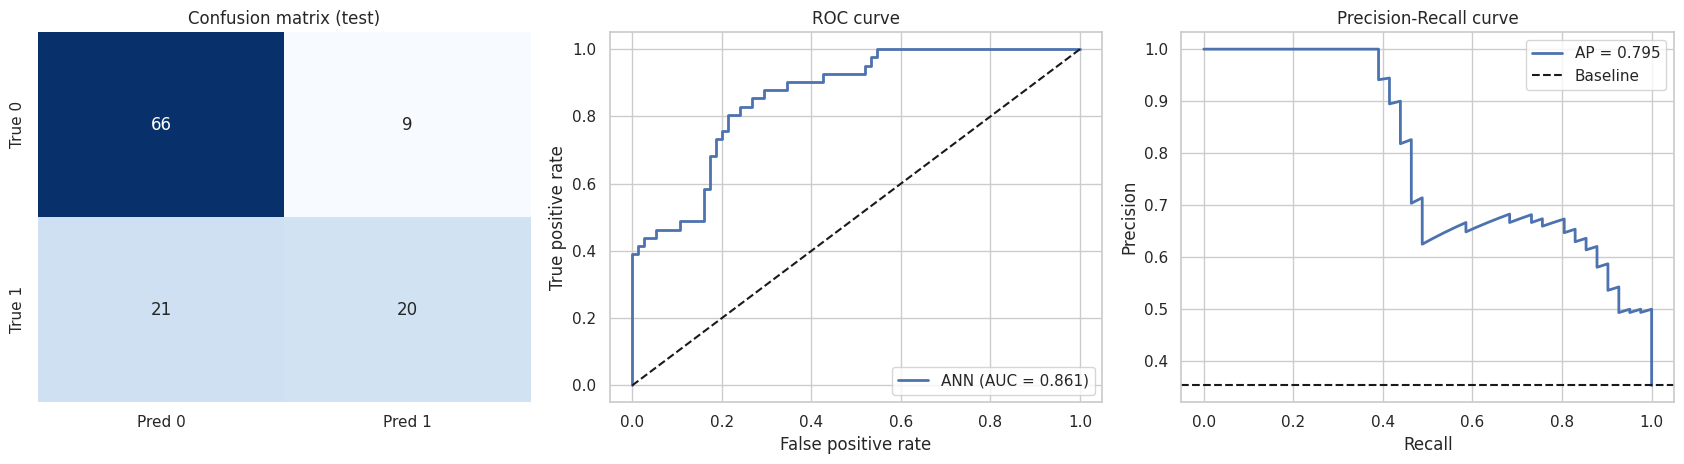

In [ ]:
fpr, tpr, _ = roc_curve(yte, proba_te); roc_auc = auc(fpr, tpr)
prec, rec, _ = precision_recall_curve(yte, proba_te); ap = average_precision_score(yte, proba_te)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cm = confusion(yte, pred_te)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
ax[0].set_title("Confusion matrix (test)")
ax[1].plot(fpr, tpr, lw=2, label=f"ANN (AUC = {roc_auc:.3f})"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate"); ax[1].legend(loc="lower right")
ax[2].plot(rec, prec, lw=2, label=f"AP = {ap:.3f}"); ax[2].axhline(yte.mean(), color="k", ls="--", label="Baseline")
ax[2].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision"); ax[2].legend()
plt.tight_layout(); plt.show()

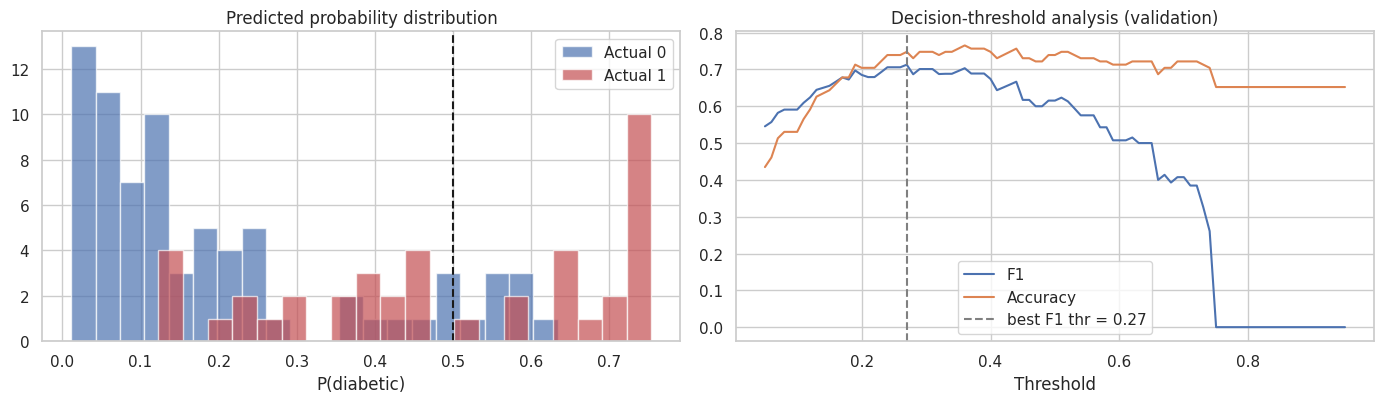

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(proba_te[yte == 0], bins=20, alpha=.7, label="Actual 0", color="#4C72B0")
ax[0].hist(proba_te[yte == 1], bins=20, alpha=.7, label="Actual 1", color="#C44E52")
ax[0].axvline(.5, color="k", ls="--"); ax[0].set(title="Predicted probability distribution", xlabel="P(diabetic)"); ax[0].legend()

# Threshold analysis on validation set
thr = np.linspace(.05, .95, 91); pv = nn.predict_proba(Xva)
f1s = [metrics(yva, (pv >= t).astype(int))["F1"] for t in thr]
accs = [metrics(yva, (pv >= t).astype(int))["Accuracy"] for t in thr]
ax[1].plot(thr, f1s, label="F1"); ax[1].plot(thr, accs, label="Accuracy")
ax[1].axvline(thr[int(np.argmax(f1s))], color="gray", ls="--", label=f"best F1 thr = {thr[int(np.argmax(f1s))]:.2f}")
ax[1].set(title="Decision-threshold analysis (validation)", xlabel="Threshold"); ax[1].legend()
plt.tight_layout(); plt.show()

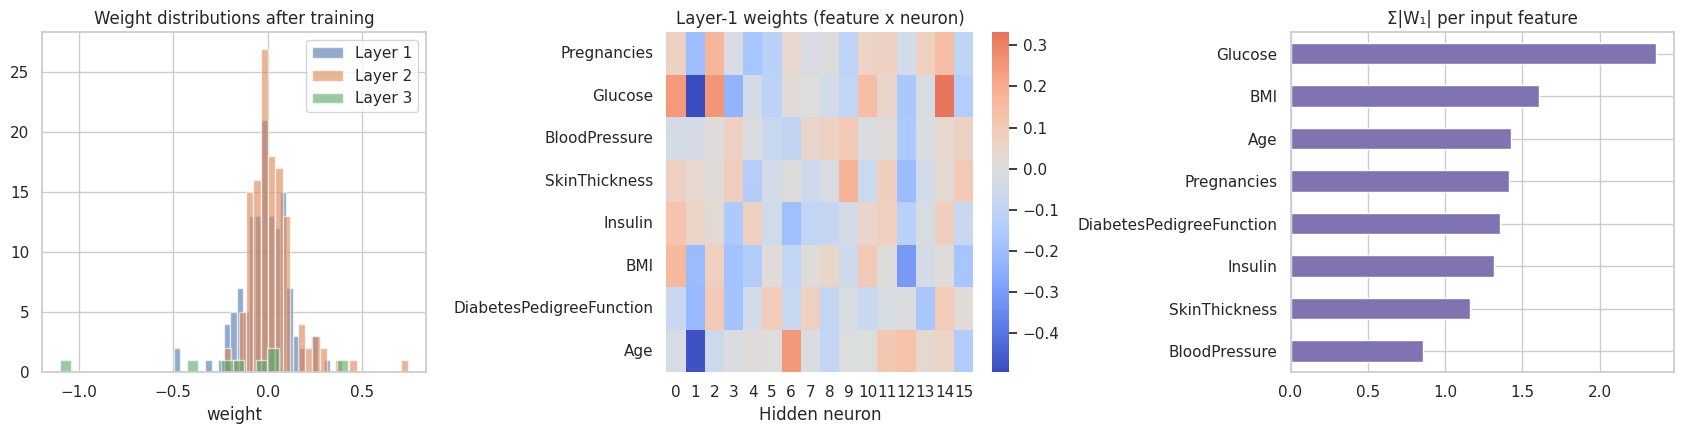

In [ ]:
# Learned weights: distribution and first-layer heatmap (feature importance proxy)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for i, W in enumerate(nn.W): ax[0].hist(W.ravel(), bins=25, alpha=.6, label=f"Layer {i+1}")
ax[0].set(title="Weight distributions after training", xlabel="weight"); ax[0].legend()
sns.heatmap(nn.W[0], cmap="coolwarm", center=0, yticklabels=features, ax=ax[1]); ax[1].set(title="Layer-1 weights (feature x neuron)", xlabel="Hidden neuron")
imp = np.abs(nn.W[0]).sum(1); pd.Series(imp, index=features).sort_values().plot(kind="barh", ax=ax[2], color="#8172B2")
ax[2].set_title("Σ|W₁| per input feature")
plt.tight_layout(); plt.show()

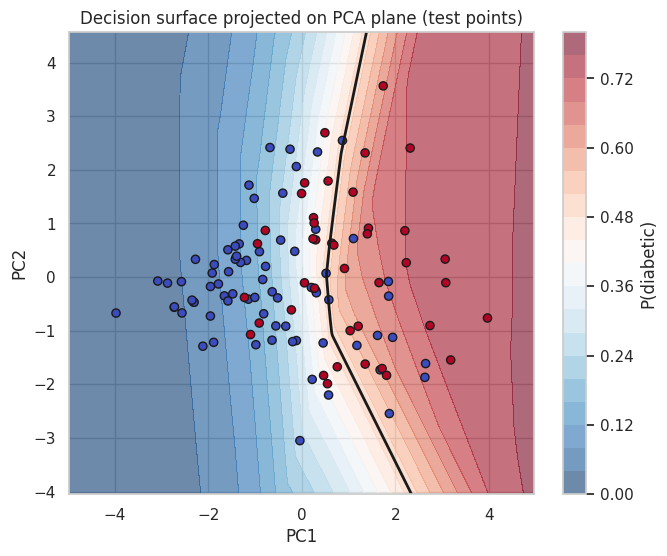

In [ ]:
# Decision regions in 2-D PCA space (visualisation only: the network is fed the 8 features,
# the grid is mapped back from PCA space to the 8-D input space)
from sklearn.decomposition import PCA
pca = PCA(2).fit(Xtr); Z = pca.transform(Xte)
gx, gy = np.meshgrid(np.linspace(Z[:,0].min()-1, Z[:,0].max()+1, 250), np.linspace(Z[:,1].min()-1, Z[:,1].max()+1, 250))
grid = pca.inverse_transform(np.c_[gx.ravel(), gy.ravel()])
pg = nn.predict_proba(grid).reshape(gx.shape)
plt.figure(figsize=(7.5, 6))
plt.contourf(gx, gy, pg, levels=20, cmap="RdBu_r", alpha=.6); plt.colorbar(label="P(diabetic)")
plt.contour(gx, gy, pg, levels=[.5], colors="k", linewidths=2)
plt.scatter(Z[:,0], Z[:,1], c=yte.ravel(), cmap="coolwarm", edgecolor="k", s=35)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Decision surface projected on PCA plane (test points)"); plt.show()

## 8. Hyper‑parameter experiments

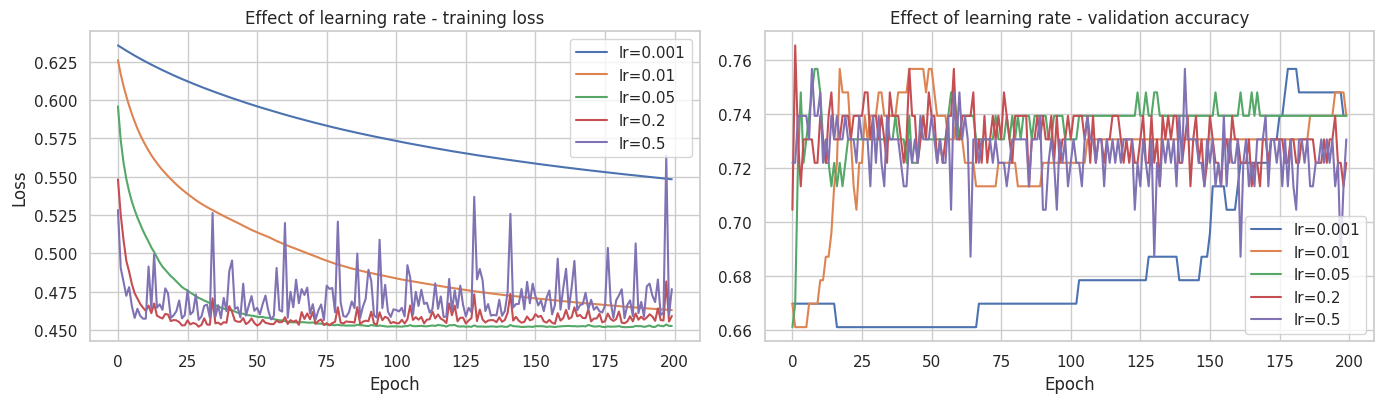

In [ ]:
# (a) Learning rate
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for lr in [0.001, 0.01, 0.05, 0.2, 0.5]:
    m = NeuralNetwork([8, 16, 8, 1], "relu", lr=lr, l2=1.0, seed=SEED).fit(Xtr, ytr, Xva, yva, epochs=200, verbose=0)
    ax[0].plot(m.history["train_loss"], label=f"lr={lr}"); ax[1].plot(m.history["val_acc"], label=f"lr={lr}")
ax[0].set(title="Effect of learning rate - training loss", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
ax[1].set(title="Effect of learning rate - validation accuracy", xlabel="Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

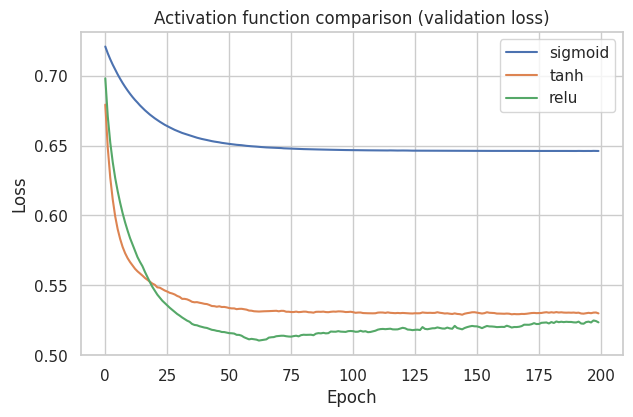

Test accuracy: {'sigmoid': np.float64(0.6466), 'tanh': np.float64(0.7672), 'relu': np.float64(0.75)}


In [ ]:
# (b) Activation functions
plt.figure(figsize=(7, 4.2))
act_res = {}
for a in ["sigmoid", "tanh", "relu"]:
    m = NeuralNetwork([8, 16, 8, 1], a, lr=0.05, l2=1.0, seed=SEED).fit(Xtr, ytr, Xva, yva, epochs=200, verbose=0)
    plt.plot(m.history["val_loss"], label=a); act_res[a] = m.accuracy(Xte, yte)
plt.title("Activation function comparison (validation loss)"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()
print("Test accuracy:", {k: round(v, 4) for k, v in act_res.items()})

,Train,Validation,Test
Architecture,,,
8-1 (logistic),0.7858,0.7130,0.7672
8-4-1,0.7840,0.7217,0.7672
8-16-1,0.7803,0.7217,0.7672
8-16-8-1,0.7784,0.7391,0.7500
8-64-32-1,0.7877,0.7565,0.7672


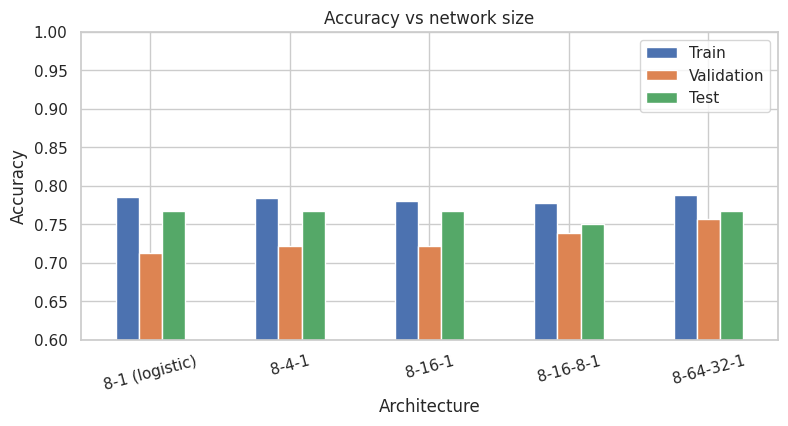

In [ ]:
# (c) Architecture / capacity
archs = {"8-1 (logistic)": [8, 1], "8-4-1": [8, 4, 1], "8-16-1": [8, 16, 1], "8-16-8-1": [8, 16, 8, 1], "8-64-32-1": [8, 64, 32, 1]}
rows = []
for name, s in archs.items():
    m = NeuralNetwork(s, "relu", lr=0.05, l2=1.0, seed=SEED).fit(Xtr, ytr, Xva, yva, epochs=200, verbose=0)
    rows.append([name, m.accuracy(Xtr, ytr), m.accuracy(Xva, yva), m.accuracy(Xte, yte)])
arch_df = pd.DataFrame(rows, columns=["Architecture", "Train", "Validation", "Test"]).set_index("Architecture")
display(arch_df.round(4))
arch_df.plot(kind="bar", figsize=(9, 4), rot=15, ylim=(.6, 1)); plt.title("Accuracy vs network size"); plt.ylabel("Accuracy"); plt.show()

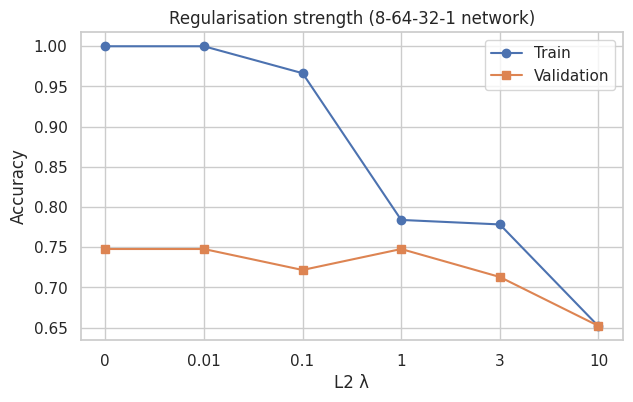

In [ ]:
# (d) L2 regularisation strength -> over-fitting control
lams = [0, 0.01, 0.1, 1, 3, 10]; tr, va = [], []
for lam in lams:
    m = NeuralNetwork([8, 64, 32, 1], "relu", lr=0.05, l2=lam, seed=SEED).fit(Xtr, ytr, epochs=300, verbose=0)
    tr.append(m.accuracy(Xtr, ytr)); va.append(m.accuracy(Xva, yva))
plt.figure(figsize=(7, 4)); plt.plot(range(len(lams)), tr, "o-", label="Train"); plt.plot(range(len(lams)), va, "s-", label="Validation")
plt.xticks(range(len(lams)), lams); plt.xlabel("L2 λ"); plt.ylabel("Accuracy"); plt.title("Regularisation strength (8-64-32-1 network)"); plt.legend(); plt.show()

## 9. Benchmark against scikit‑learn

,Accuracy,Precision,Recall,Specificity,F1,AUC
Model,,,,,,
Our ANN (NumPy backprop),0.7414,0.6897,0.4878,0.8800,0.5714,0.8608
sklearn MLPClassifier,0.7672,0.7059,0.5854,0.8667,0.6400,0.8647
Logistic Regression,0.7672,0.7333,0.5366,0.8933,0.6197,0.8709
Random Forest,0.7414,0.6774,0.5122,0.8667,0.5833,0.8309


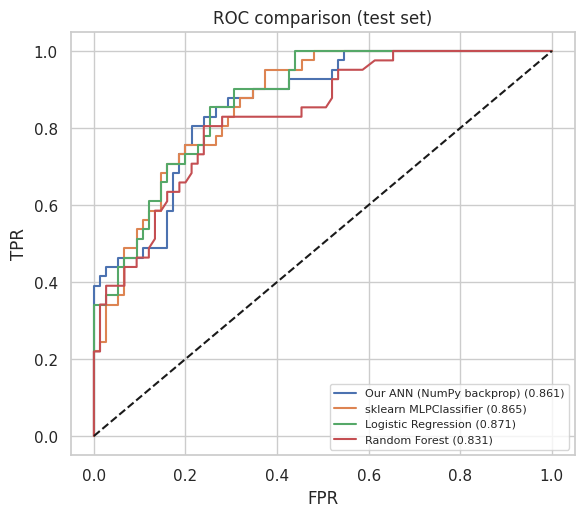

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Our ANN (NumPy backprop)": None,
    "sklearn MLPClassifier": MLPClassifier((16, 8), alpha=0.01, max_iter=500, random_state=SEED).fit(Xtr, y_train),
    "Logistic Regression": LogisticRegression(max_iter=1000).fit(Xtr, y_train),
    "Random Forest": RandomForestClassifier(300, random_state=SEED).fit(Xtr, y_train),
}
rows, plt_data = [], {}
for name, mdl in models.items():
    p = nn.predict_proba(Xte).ravel() if mdl is None else mdl.predict_proba(Xte)[:, 1]
    pred = (p >= .5).astype(int); m = metrics(yte, pred)
    f, t, _ = roc_curve(yte, p); plt_data[name] = (f, t, auc(f, t))
    rows.append({"Model": name, **m, "AUC": auc(f, t)})
bench = pd.DataFrame(rows).set_index("Model"); display(bench.round(4))

plt.figure(figsize=(6.5, 5.5))
for n_, (f, t, a) in plt_data.items(): plt.plot(f, t, label=f"{n_} ({a:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC comparison (test set)"); plt.legend(fontsize=8); plt.show()

## 10. Conclusions
- The ANN, built only with NumPy, passes **gradient checking** for sigmoid, tanh and ReLU – confirming that the backpropagation implementation is correct.
- Preprocessing mattered: treating zeros as missing values, median imputation, outlier clipping and standardisation (all fit on training data only) make gradient descent stable.
- Learning curves show convergence and the effect of regularisation; with early stopping and L2 regularisation the gap between training and validation accuracy shrinks, and test accuracy/AUC are close to logistic regression and sklearn's MLP, which is typical for this small, noisy tabular dataset (~768 rows) – the ceiling is ~75–80 % accuracy.
- Possible extensions: momentum/Adam optimiser, early stopping, k‑fold cross‑validation, SMOTE / class weights for the class imbalance.